# Boris sc PCA, t-SNE, and EOT analysis

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

from ne_aligned_utils.analysis import (
    NCovAnalysisData,
    build_ot_tsne_four_block_matrix,
    compute_eot_embeddings,
    compute_ot_plan_from_arrays,
    compute_pca_embeddings,
    compute_tsne_embeddings,
    normalize_ot_tsne_graph,
    plot_embedding_panels,
    plot_joint_embedding_pair,
    plot_matrix,
    plot_ot_tsne_sweep_grid,
    run_tsne_from_graph,
    sparsify_four_block_top_neighbors,
)

In [3]:
def resolve_human_brain_path(data_path: str | Path = "data/human_brain") -> Path:
    path = Path(data_path)
    candidates = [path]

    if not path.is_absolute():
        cwd = Path.cwd()
        base_dirs = [cwd, cwd.parent, cwd.parent.parent]
        for base in base_dirs:
            candidates.append(base / path)
            if path.name != "human_brain":
                candidates.append(base / "data" / "human_brain")

    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()

    checked = ", ".join(str(candidate) for candidate in candidates)
    raise FileNotFoundError(f"Could not find human_brain data. Checked: {checked}")


def load_boris_sc_analysis_data(data_path: str | Path = "data/human_brain") -> NCovAnalysisData:
    resolved_path = resolve_human_brain_path(data_path)

    x1 = np.load(resolved_path / "X1.npy")
    x2 = np.load(resolved_path / "X2.npy")

    cell_metadata = pd.read_csv(resolved_path / "cell_metadata.csv", index_col=0)
    cells_metadata = pd.read_csv(resolved_path / "cells_metadata.csv", index_col=0)
    cells_metadata = cells_metadata.join(cell_metadata[["cell_types"]], how="left")

    if cells_metadata["cell_types"].isna().any():
        raise ValueError("Some human_brain cells are missing cell type annotations after aligning metadata.")

    method = cells_metadata["method"].astype(str).to_numpy()
    cell_type_values = cells_metadata["cell_types"].astype(str)
    cell_type_names = tuple(sorted(cell_type_values.unique()))
    cell_type_to_label = {name: idx for idx, name in enumerate(cell_type_names)}
    labels = cell_type_values.map(cell_type_to_label).to_numpy(dtype=int)

    labels1 = labels[method == "data1"]
    labels2 = labels[method == "data2"]

    if labels1.shape[0] != x1.shape[0] or labels2.shape[0] != x2.shape[0]:
        raise ValueError(
            "Metadata-derived label counts do not match X1/X2 shapes: "
            f"labels1={labels1.shape[0]}, x1={x1.shape[0]}, labels2={labels2.shape[0]}, x2={x2.shape[0]}"
        )

    return NCovAnalysisData(
        x1=np.asarray(x1),
        x2=np.asarray(x2),
        labels1=np.asarray(labels1, dtype=int),
        labels2=np.asarray(labels2, dtype=int),
        cell_type_names=cell_type_names,
        dataset_names=("human_brain-data1", "human_brain-data2"),
    )


boris_sc = load_boris_sc_analysis_data()
boris_sc.dataset_names, boris_sc.short_dataset_names

(('human_brain-data1', 'human_brain-data2'), ('data1', 'data2'))

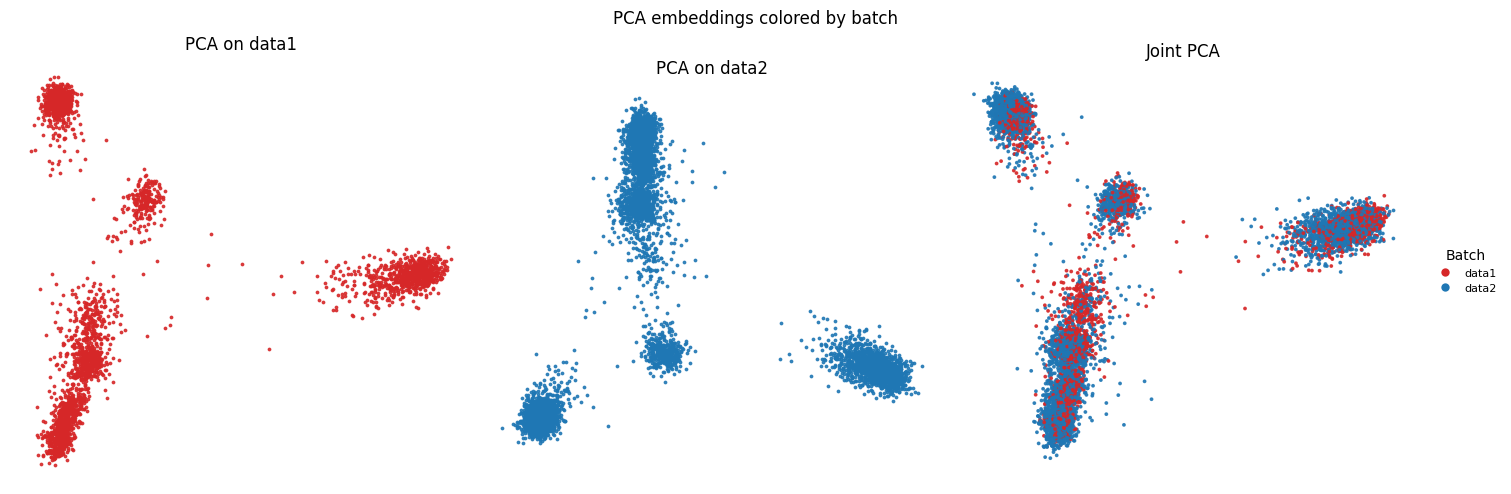

In [5]:
pca_embeddings = compute_pca_embeddings(boris_sc, n_components=50, random_state=0)
fig, _ = plot_embedding_panels(pca_embeddings, boris_sc, color_by="batch")

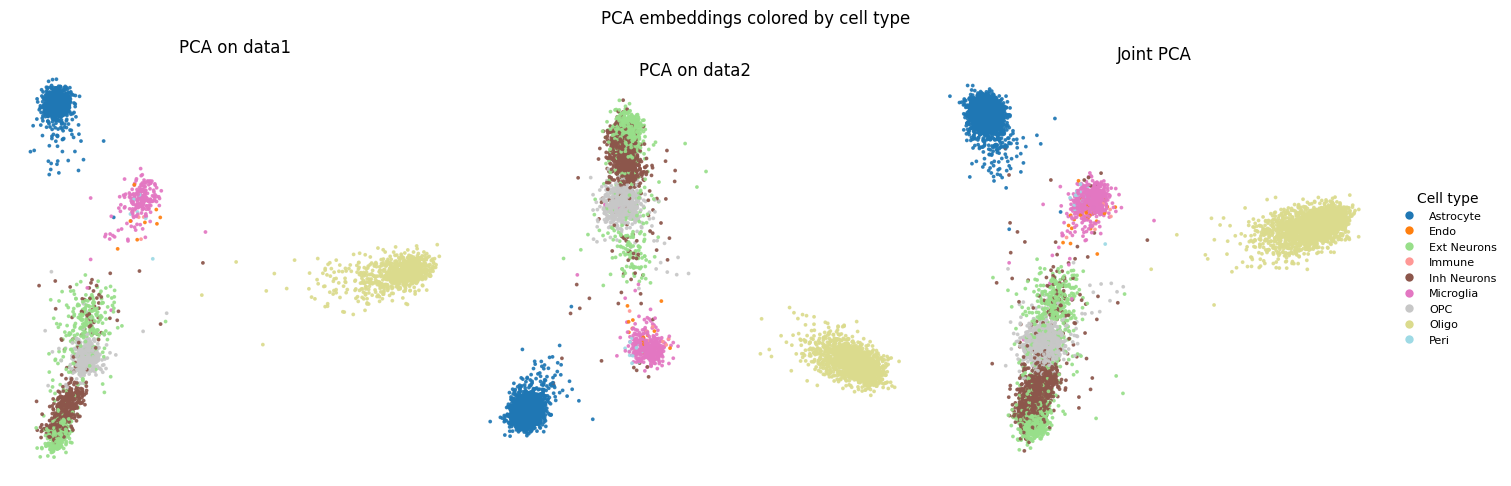

In [6]:
fig, _ = plot_embedding_panels(pca_embeddings, boris_sc, color_by="cell_type")

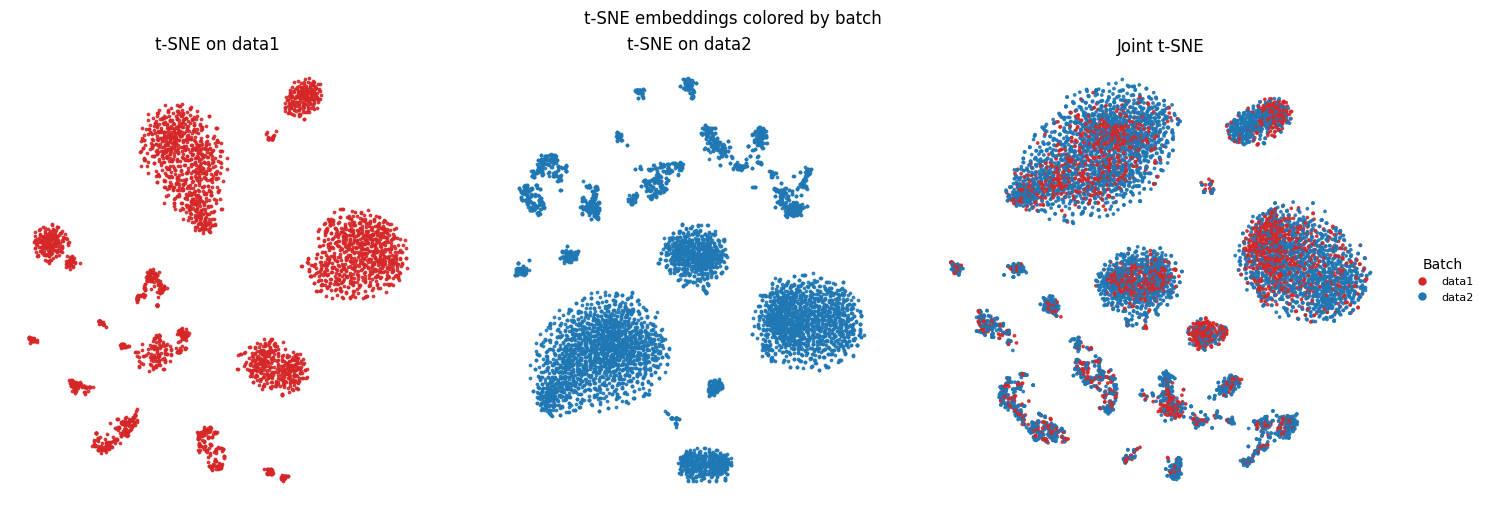

In [7]:
tsne_embeddings = compute_tsne_embeddings(pca_embeddings, random_state=0)
fig, _ = plot_embedding_panels(tsne_embeddings, boris_sc, color_by="batch")

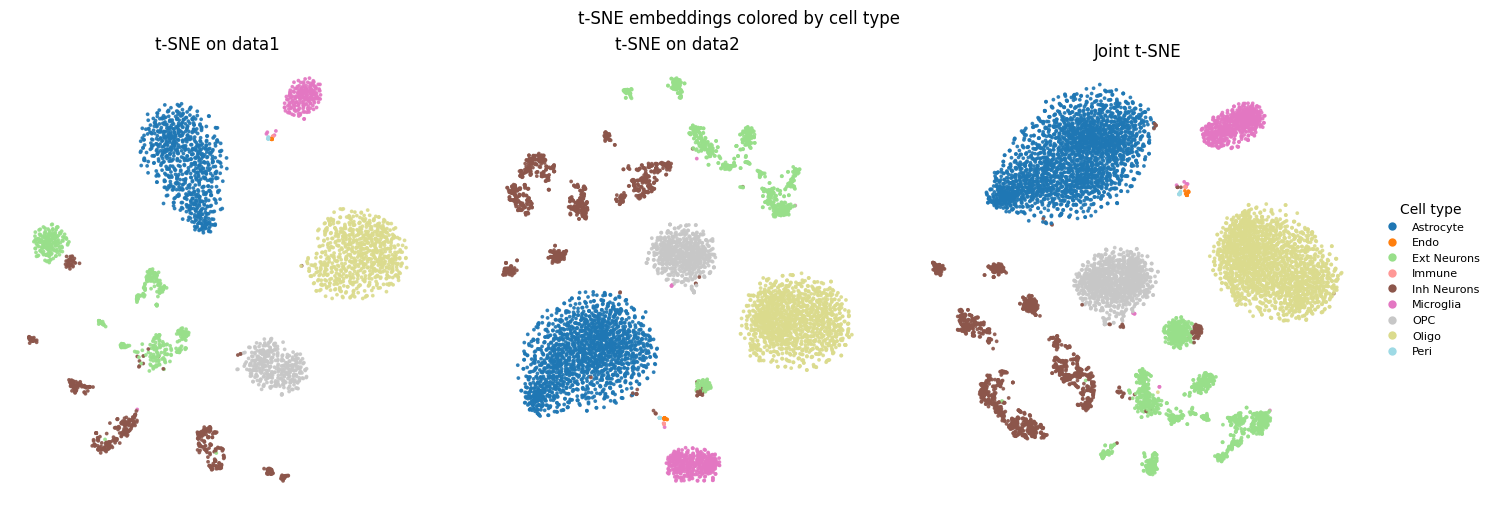

In [8]:
fig, _ = plot_embedding_panels(tsne_embeddings, boris_sc, color_by="cell_type")

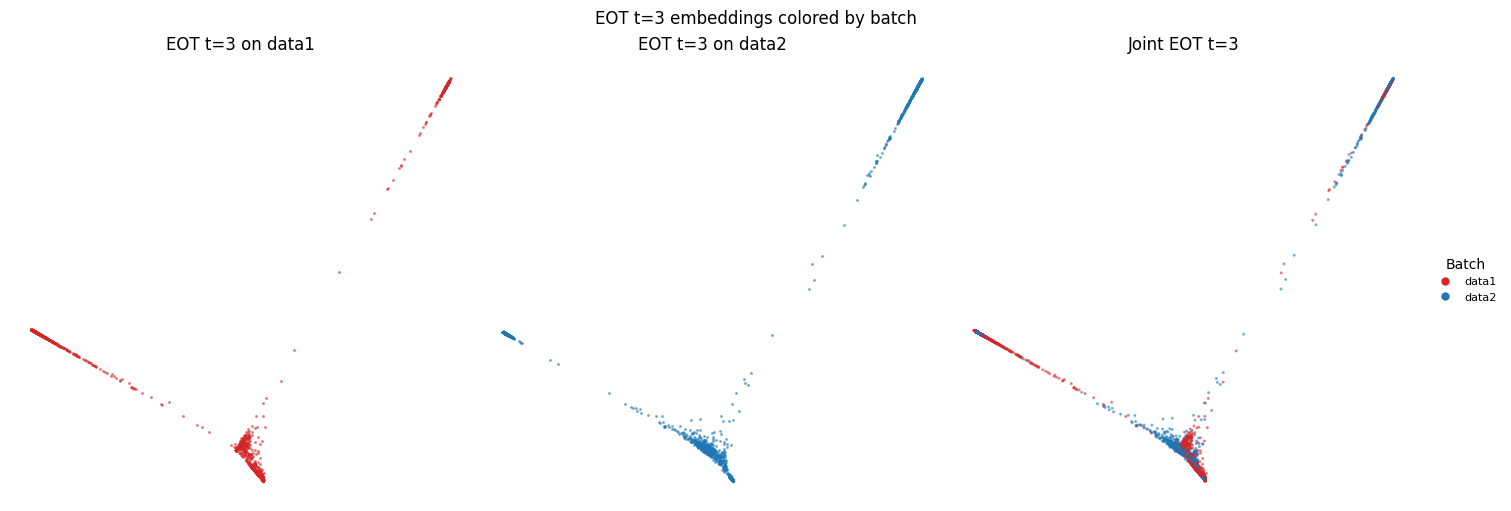

In [9]:
eot_embeddings = compute_eot_embeddings(pca_embeddings, t=3, eps_times=10.0)
fig, _ = plot_embedding_panels(
    eot_embeddings,
    boris_sc,
    color_by="batch",
    point_size=1.5,
    alpha=0.45,
    standardize=True,
    aspect="auto",
)

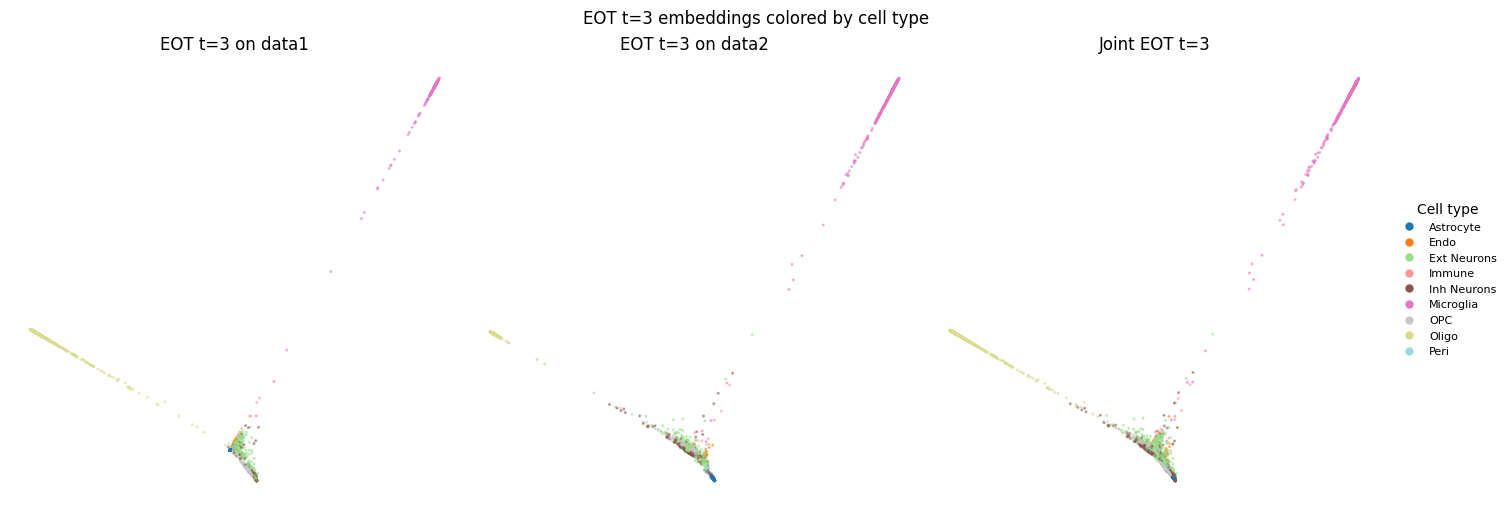

In [10]:
fig, _ = plot_embedding_panels(
    eot_embeddings,
    boris_sc,
    color_by="cell_type",
    point_size=1.5,
    alpha=0.45,
    standardize=True,
    aspect="auto",
)

### OT-TSNE

#### Step 1: Calculate OT Plan

shape=(3145, 6070), sum=1.000000, nnz=19090150


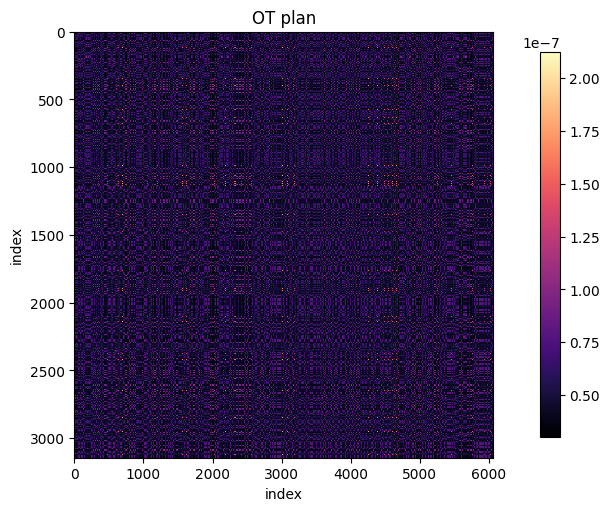

In [11]:
ot_plan = compute_ot_plan_from_arrays(boris_sc.x1, boris_sc.x2, eps_times=1.0, tol=1e-12, max_iter=int(1e4))
print(f"shape={ot_plan.shape}, sum={ot_plan.sum():.6f}, nnz={np.count_nonzero(ot_plan)}")
fig, _ = plot_matrix(ot_plan, title="OT plan")

#### Step 2: Build 4 Block Matrix

shape=(9215, 9215), sum=4.447066, nnz=84907010


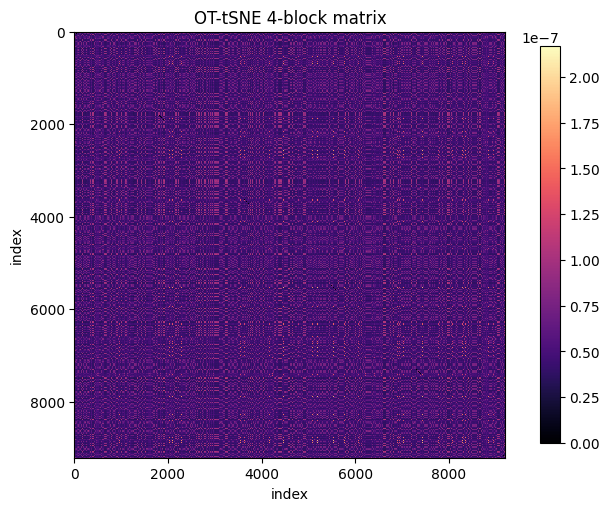

In [12]:
ot_tsne_four_block = build_ot_tsne_four_block_matrix(ot_plan)
print(
    f"shape={ot_tsne_four_block.shape}, sum={ot_tsne_four_block.sum():.6f}, "
    f"nnz={np.count_nonzero(ot_tsne_four_block)}"
)
fig, _ = plot_matrix(ot_tsne_four_block, title="OT-tSNE 4-block matrix")

#### Step 3: Sparsify 4 Block Matrix (top 15% neighbors)

shape=(9215, 9215), sum=764586.000000, nnz=764586


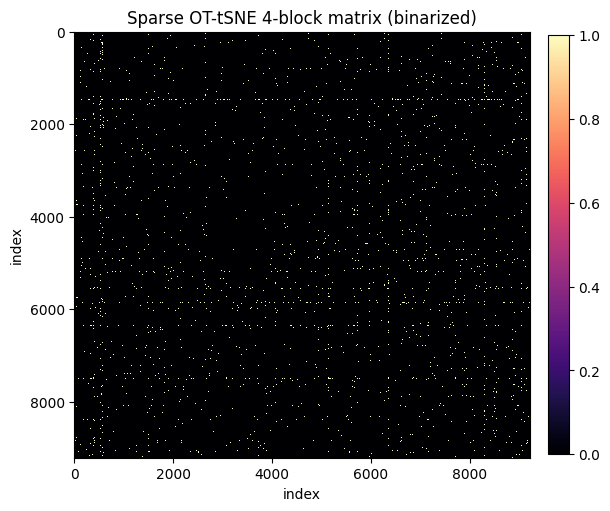

In [13]:
ot_tsne_sparse_four_block = sparsify_four_block_top_neighbors(
    ot_tsne_four_block,
    n0=boris_sc.x1.shape[0],
    n1=boris_sc.x2.shape[0],
    percentage=0.005,
    ensure_nonempty=True,
    binarize=True,
)
print(
    f"shape={ot_tsne_sparse_four_block.shape}, sum={ot_tsne_sparse_four_block.sum():.6f}, "
    f"nnz={np.count_nonzero(ot_tsne_sparse_four_block)}"
)
fig, _ = plot_matrix(ot_tsne_sparse_four_block, title="Sparse OT-tSNE 4-block matrix (binarized)")

#### Step 4: Normalize

shape=(9215, 9215), sum=1.000000, nnz=764586


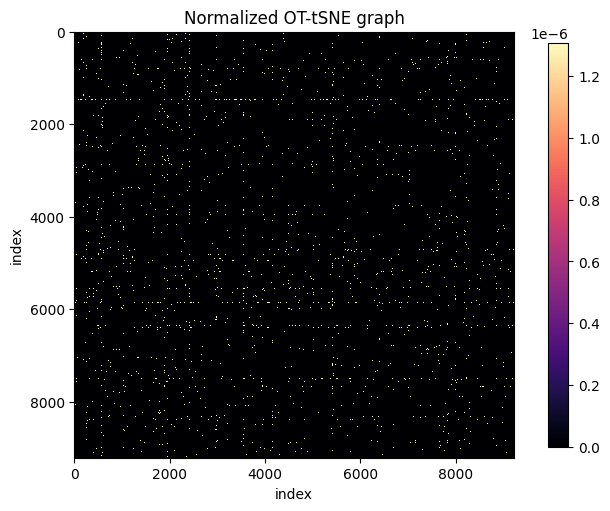

In [14]:
ot_tsne_graph = normalize_ot_tsne_graph(ot_tsne_sparse_four_block)
print(f"shape={ot_tsne_graph.shape}, sum={ot_tsne_graph.sum():.6f}, nnz={np.count_nonzero(ot_tsne_graph)}")
fig, _ = plot_matrix(ot_tsne_graph, title="Normalized OT-tSNE graph")

#### Step 5: t-SNE

In [15]:
ot_tsne_embedding = run_tsne_from_graph(ot_tsne_graph, random_state=0, n_epochs=200)
ot_tsne_embedding.shape

(9215, 2)

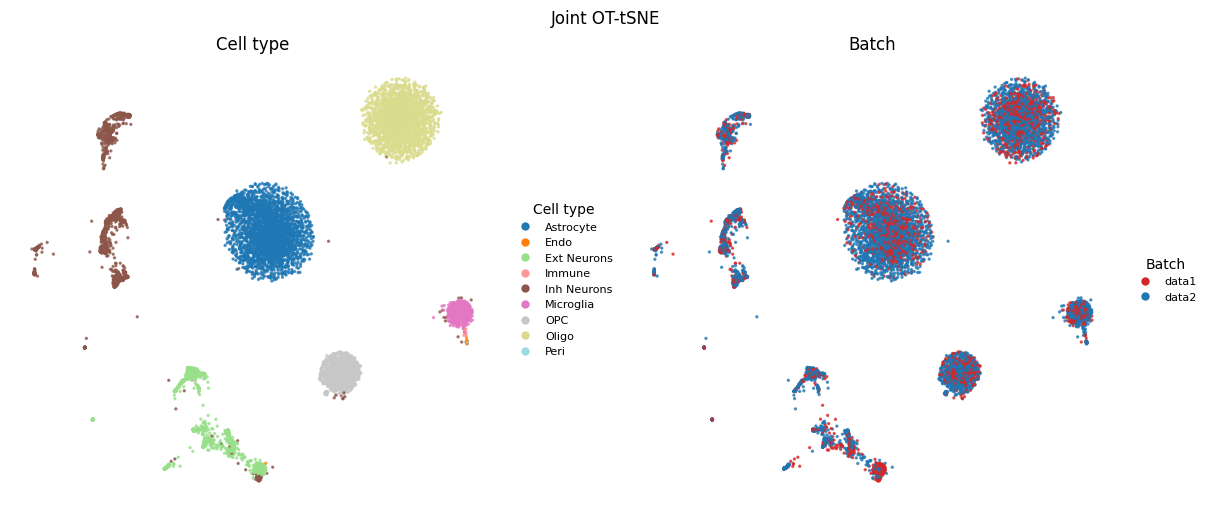

In [16]:
fig, _ = plot_joint_embedding_pair(
    ot_tsne_embedding,
    boris_sc,
    point_size=2.0,
    alpha=0.7,
    aspect="auto",
)

#### OT-tSNE Sweep

In [ ]:
ot_tsne_sweep_embeddings, fig, _ = plot_ot_tsne_sweep_grid(
    boris_sc,
    percentages=(0.001, 0.005, 0.01, 0.05, 0.1, 0.15, 0.2),
    eps_values=(1.0, 10.0, 100.0, 300.0),
    point_size=1.5,
    alpha=0.7,
    binarize=True,
    aspect="auto",
)

In [ ]:
ot_tsne_sweep_embeddings, fig, _ = plot_ot_tsne_sweep_grid(
    boris_sc,
    percentages=(0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.4),
    eps_values=(0.001, 0.1, 1.0, 10.0, 100.0, 300.0),
    point_size=1.5,
    alpha=0.7,
    binarize=False,
    aspect="auto",
)

#### Benchmarking

### Embedding Metrics

In [4]:
from pathlib import Path

import numpy as np

from ne_aligned_utils.analysis import (
    compute_eot_embeddings,
    compute_ot_tsne_embedding_from_arrays,
    compute_pca_embeddings,
)

embedding_metric_percentages = (0.001, 0.005, 0.01, 0.05, 0.1, 0.15, 0.2)
embedding_metric_eps_values = (1.0, 10.0, 100.0, 300.0)
embedding_metric_k = 50
embedding_metric_random_state = 0
embedding_metric_n_epochs = 200
embedding_metric_binarize = True
embedding_metric_eot_t = 3

embedding_metric_cache_dir = resolve_human_brain_path()
embedding_metric_cache_dir.mkdir(parents=True, exist_ok=True)
embedding_metric_figure_dir = embedding_metric_cache_dir / "figures"
embedding_metric_figure_dir.mkdir(parents=True, exist_ok=True)

embedding_metric_variant = "binarized" if embedding_metric_binarize else "weighted"
embedding_metric_cache_path = (
    embedding_metric_cache_dir
    / f"joint_ot_tsne_sweep_embeddings_{embedding_metric_variant}.npz"
)

metric_base_embeddings = globals().get("pca_embeddings")
if metric_base_embeddings is None:
    metric_base_embeddings = compute_pca_embeddings(boris_sc, n_components=50, random_state=0)

expected_shape = (
    len(embedding_metric_eps_values),
    len(embedding_metric_percentages),
    boris_sc.joint_data.shape[0],
    2,
)

if embedding_metric_cache_path.exists():
    with np.load(embedding_metric_cache_path) as cache:
        cached_eps_values = tuple(float(value) for value in cache["eps_values"])
        cached_percentages = tuple(float(value) for value in cache["percentages"])
        cached_binarize = bool(cache["binarize"].item())
        cached_eot_t = int(cache["eot_t"])
        ot_tsne_metric_embeddings = np.asarray(cache["ot_tsne_embeddings"], dtype=float)
        eot_metric_embeddings = np.asarray(cache["eot_embeddings"], dtype=float)

    cache_matches_request = (
        cached_eps_values == embedding_metric_eps_values
        and cached_percentages == embedding_metric_percentages
        and cached_binarize == embedding_metric_binarize
        and cached_eot_t == embedding_metric_eot_t
        and ot_tsne_metric_embeddings.shape == expected_shape
        and eot_metric_embeddings.shape
        == (len(embedding_metric_eps_values), boris_sc.joint_data.shape[0], 2)
    )
else:
    cache_matches_request = False

if not cache_matches_request:
    print("Cache missing or settings changed; computing joint OT-tSNE metric embeddings...")
    ot_tsne_metric_embeddings = np.empty(expected_shape, dtype=float)
    eot_metric_embeddings = np.empty(
        (len(embedding_metric_eps_values), boris_sc.joint_data.shape[0], 2),
        dtype=float,
    )
    total_progress_steps = len(embedding_metric_eps_values) * (
        1 + len(embedding_metric_percentages)
    )
    progress_step = 0

    for eps_idx, eps_times in enumerate(embedding_metric_eps_values):
        progress_step += 1
        print(
            f"[{progress_step}/{total_progress_steps}] Computing EOT t={embedding_metric_eot_t} "
            f"reference for eps_times={eps_times:g}"
        )
        eot_metric_embeddings[eps_idx] = compute_eot_embeddings(
            metric_base_embeddings,
            t=embedding_metric_eot_t,
            eps_times=eps_times,
        ).joint

        for pct_idx, percentage in enumerate(embedding_metric_percentages):
            progress_step += 1
            print(
                f"[{progress_step}/{total_progress_steps}] Computing joint OT-tSNE embedding "
                f"for eps_times={eps_times:g}, top {100.0 * percentage:g}% neighbors"
            )
            ot_tsne_metric_embeddings[eps_idx, pct_idx] = (
                compute_ot_tsne_embedding_from_arrays(
                    boris_sc.x1,
                    boris_sc.x2,
                    eps_times=eps_times,
                    percentage=percentage,
                    binarize=embedding_metric_binarize,
                    random_state=embedding_metric_random_state,
                    n_epochs=embedding_metric_n_epochs,
                )
            )

    np.savez_compressed(
        embedding_metric_cache_path,
        eps_values=np.asarray(embedding_metric_eps_values, dtype=float),
        percentages=np.asarray(embedding_metric_percentages, dtype=float),
        ot_tsne_embeddings=ot_tsne_metric_embeddings,
        eot_embeddings=eot_metric_embeddings,
        binarize=np.asarray(embedding_metric_binarize),
        metric_k=np.asarray(embedding_metric_k, dtype=int),
        eot_t=np.asarray(embedding_metric_eot_t, dtype=int),
        random_state=np.asarray(embedding_metric_random_state, dtype=int),
        n_epochs=np.asarray(embedding_metric_n_epochs, dtype=int),
    )
    print(f"Saved joint OT-tSNE metric embeddings to {embedding_metric_cache_path}")
else:
    print(f"Loaded joint OT-tSNE metric embeddings from {embedding_metric_cache_path}")

print(
    f"variant={embedding_metric_variant}, eps_times={embedding_metric_eps_values}, "
    f"percentages={embedding_metric_percentages}, k={embedding_metric_k}, "
    f"OT grid shape={ot_tsne_metric_embeddings.shape}, "
    f"EOT grid shape={eot_metric_embeddings.shape}"
)

Cache missing or settings changed; computing joint OT-tSNE metric embeddings...
[1/32] Computing EOT t=3 reference for eps_times=1
[2/32] Computing joint OT-tSNE embedding for eps_times=1, top 0.1% neighbors
[3/32] Computing joint OT-tSNE embedding for eps_times=1, top 0.5% neighbors
[4/32] Computing joint OT-tSNE embedding for eps_times=1, top 1% neighbors
[5/32] Computing joint OT-tSNE embedding for eps_times=1, top 5% neighbors
[6/32] Computing joint OT-tSNE embedding for eps_times=1, top 10% neighbors
[7/32] Computing joint OT-tSNE embedding for eps_times=1, top 15% neighbors
[8/32] Computing joint OT-tSNE embedding for eps_times=1, top 20% neighbors
[9/32] Computing EOT t=3 reference for eps_times=10
[10/32] Computing joint OT-tSNE embedding for eps_times=10, top 0.1% neighbors
[11/32] Computing joint OT-tSNE embedding for eps_times=10, top 0.5% neighbors
[12/32] Computing joint OT-tSNE embedding for eps_times=10, top 1% neighbors
[13/32] Computing joint OT-tSNE embedding for eps_

/home/berens/bep526/ot-tSNE/ne-aligned/.venv/lib/python3.14/site-packages/ot/bregman/_sinkhorn.py:630: RuntimeWarning: divide by zero encountered in divide
  v = b / KtransposeU
/home/berens/bep526/ot-tSNE/ne-aligned/.venv/lib/python3.14/site-packages/ot/backend.py:1197: RuntimeWarning: invalid value encountered in dot
  return np.dot(a, b)
/home/berens/bep526/ot-tSNE/ne-aligned/.venv/lib/python3.14/site-packages/ot/bregman/_sinkhorn.py:642: UserWarning: Warning: numerical errors at iteration 0
  warnings.warn("Warning: numerical errors at iteration %d" % ii)


[26/32] Computing joint OT-tSNE embedding for eps_times=300, top 0.1% neighbors


/home/berens/bep526/ot-tSNE/ne-aligned/.venv/lib/python3.14/site-packages/ot/bregman/_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


[27/32] Computing joint OT-tSNE embedding for eps_times=300, top 0.5% neighbors
[28/32] Computing joint OT-tSNE embedding for eps_times=300, top 1% neighbors
[29/32] Computing joint OT-tSNE embedding for eps_times=300, top 5% neighbors
[30/32] Computing joint OT-tSNE embedding for eps_times=300, top 10% neighbors
[31/32] Computing joint OT-tSNE embedding for eps_times=300, top 15% neighbors
[32/32] Computing joint OT-tSNE embedding for eps_times=300, top 20% neighbors
Saved joint OT-tSNE metric embeddings to /weka/berens/bep526/ot-tSNE/ne-aligned/data/human_brain/joint_ot_tsne_sweep_embeddings_binarized.npz
variant=binarized, eps_times=(1.0, 10.0, 100.0, 300.0), percentages=(0.001, 0.005, 0.01, 0.05, 0.1, 0.15, 0.2), k=50, OT grid shape=(4, 7, 9215, 2), EOT grid shape=(4, 9215, 2)


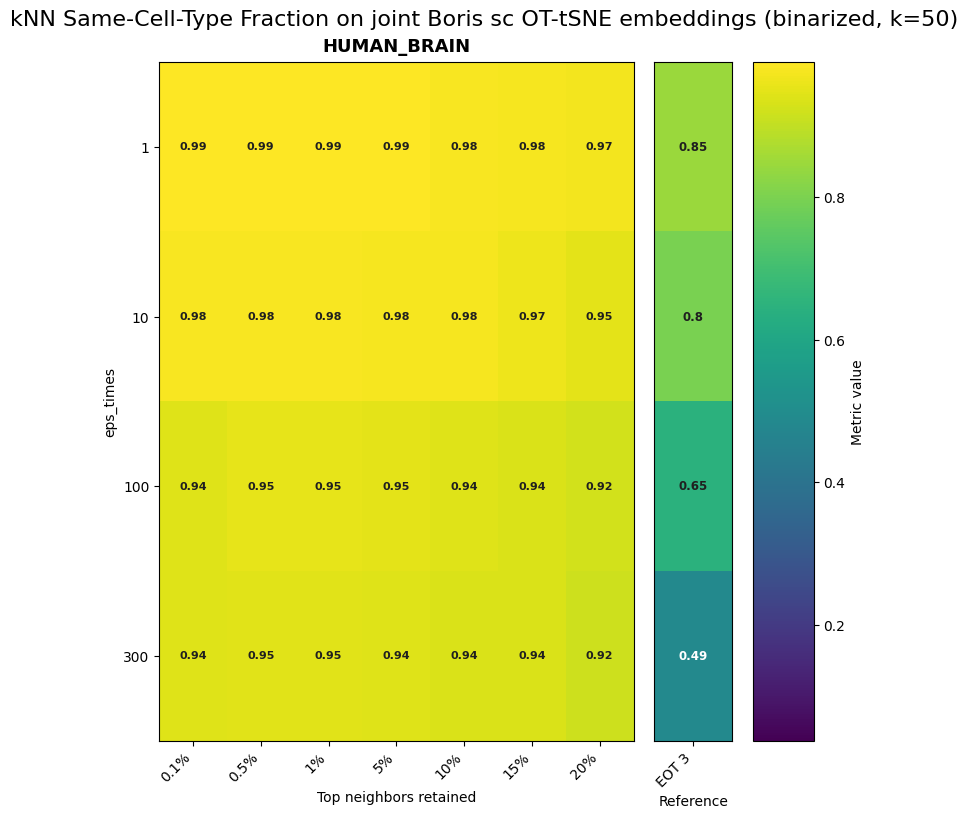

Saved same_cell_type heatmap figure to /weka/berens/bep526/ot-tSNE/ne-aligned/data/human_brain/figures/same_cell_type_joint_ot_tsne_eps_pct_heatmap_binarized.png


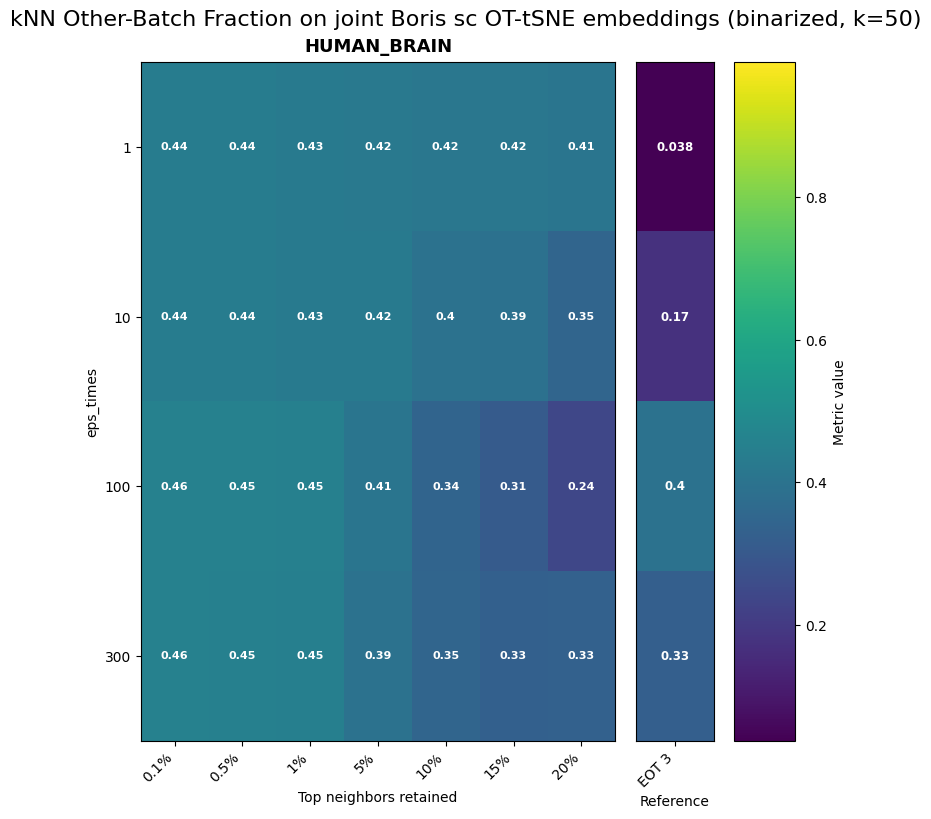

Saved other_batch heatmap figure to /weka/berens/bep526/ot-tSNE/ne-aligned/data/human_brain/figures/other_batch_joint_ot_tsne_eps_pct_heatmap_binarized.png
Saved embedding-metric heatmap matrices to /weka/berens/bep526/ot-tSNE/ne-aligned/data/human_brain/joint_ot_tsne_knn_metric_heatmaps_binarized.npz


In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from ne_aligned_utils.benchmarking import (
    compute_shared_dataset_scale_bounds,
    plot_metric_heatmap_grid,
)
from ne_aligned_utils.metrics import (
    compute_knn_other_batch_fraction,
    compute_knn_same_cell_type_fraction,
)

embedding_metric_cache_dir = resolve_human_brain_path()
embedding_metric_figure_dir = embedding_metric_cache_dir / "figures"
embedding_metric_figure_dir.mkdir(parents=True, exist_ok=True)

embedding_metric_variant = globals().get("embedding_metric_variant", "binarized")
embedding_metric_cache_path = (
    embedding_metric_cache_dir
    / f"joint_ot_tsne_sweep_embeddings_{embedding_metric_variant}.npz"
)
if not embedding_metric_cache_path.exists():
    raise FileNotFoundError(
        f"No saved OT-tSNE embedding cache found at {embedding_metric_cache_path}. "
        "Run the previous cell first."
    )

with np.load(embedding_metric_cache_path) as cache:
    embedding_metric_eps_values = np.asarray(cache["eps_values"], dtype=float)
    embedding_metric_percentages = np.asarray(cache["percentages"], dtype=float)
    ot_tsne_metric_embeddings = np.asarray(cache["ot_tsne_embeddings"], dtype=float)
    eot_metric_embeddings = np.asarray(cache["eot_embeddings"], dtype=float)
    embedding_metric_binarize = bool(cache["binarize"].item())
    embedding_metric_k = int(cache["metric_k"])
    embedding_metric_eot_t = int(cache["eot_t"])

metric_specs = {
    "same_cell_type": {
        "label": "kNN Same-Cell-Type Fraction",
        "fn": lambda emb: compute_knn_same_cell_type_fraction(
            emb,
            boris_sc.joint_labels,
            k=embedding_metric_k,
        ),
        "cmap": "viridis",
    },
    "other_batch": {
        "label": "kNN Other-Batch Fraction",
        "fn": lambda emb: compute_knn_other_batch_fraction(
            emb,
            boris_sc.batch_ids,
            k=embedding_metric_k,
        ),
        "cmap": "viridis",
    },
}

heatmap_data_by_metric = {}
for metric_name, spec in metric_specs.items():
    matrix = np.empty((len(embedding_metric_eps_values), len(embedding_metric_percentages)), dtype=float)
    eot_column = np.empty(len(embedding_metric_eps_values), dtype=float)

    for eps_idx in range(len(embedding_metric_eps_values)):
        eot_column[eps_idx] = spec["fn"](eot_metric_embeddings[eps_idx])
        for pct_idx in range(len(embedding_metric_percentages)):
            matrix[eps_idx, pct_idx] = spec["fn"](
                ot_tsne_metric_embeddings[eps_idx, pct_idx]
            )

    heatmap_data_by_metric[metric_name] = {
        "metric_name": metric_name,
        "metric_label": spec["label"],
        "eps_times": embedding_metric_eps_values,
        "pct_values": 100.0 * embedding_metric_percentages,
        "eot_t": embedding_metric_eot_t,
        "dataset_names": ("human_brain",),
        "datasets": {
            "human_brain": {
                "top_pct_matrix": matrix,
                "eot_column": eot_column,
            }
        },
        "y_labels": [f"{eps:g}" for eps in embedding_metric_eps_values],
        "top_pct_column_count": int(len(embedding_metric_percentages)),
    }

embedding_metric_scale_bounds = compute_shared_dataset_scale_bounds(heatmap_data_by_metric)
embedding_metric_heatmap_cache_path = (
    embedding_metric_cache_dir
    / f"joint_ot_tsne_knn_metric_heatmaps_{embedding_metric_variant}.npz"
)

for metric_name, heatmap_data in heatmap_data_by_metric.items():
    figure_path = (
        embedding_metric_figure_dir
        / f"{metric_name}_joint_ot_tsne_eps_pct_heatmap_{embedding_metric_variant}.png"
    )
    fig, axes = plot_metric_heatmap_grid(
        heatmap_data,
        title=(
            f"{heatmap_data['metric_label']} on joint Boris sc OT-tSNE embeddings "
            f"({embedding_metric_variant}, k={embedding_metric_k})"
        ),
        cmap=metric_specs[metric_name]["cmap"],
        save_path=figure_path,
        scale_bounds_by_dataset=embedding_metric_scale_bounds,
        annotate_cells=True,
    )
    axes["human_brain"]["main"].set_ylabel("eps_times")
    plt.show()
    print(f"Saved {metric_name} heatmap figure to {figure_path}")

np.savez_compressed(
    embedding_metric_heatmap_cache_path,
    eps_values=embedding_metric_eps_values,
    percentages=embedding_metric_percentages,
    pct_values_percent=100.0 * embedding_metric_percentages,
    metric_k=np.asarray(embedding_metric_k, dtype=int),
    eot_t=np.asarray(embedding_metric_eot_t, dtype=int),
    binarize=np.asarray(embedding_metric_binarize),
    same_cell_type_matrix=heatmap_data_by_metric["same_cell_type"]["datasets"]["human_brain"]["top_pct_matrix"],
    same_cell_type_eot=heatmap_data_by_metric["same_cell_type"]["datasets"]["human_brain"]["eot_column"],
    other_batch_matrix=heatmap_data_by_metric["other_batch"]["datasets"]["human_brain"]["top_pct_matrix"],
    other_batch_eot=heatmap_data_by_metric["other_batch"]["datasets"]["human_brain"]["eot_column"],
)
print(f"Saved embedding-metric heatmap matrices to {embedding_metric_heatmap_cache_path}")

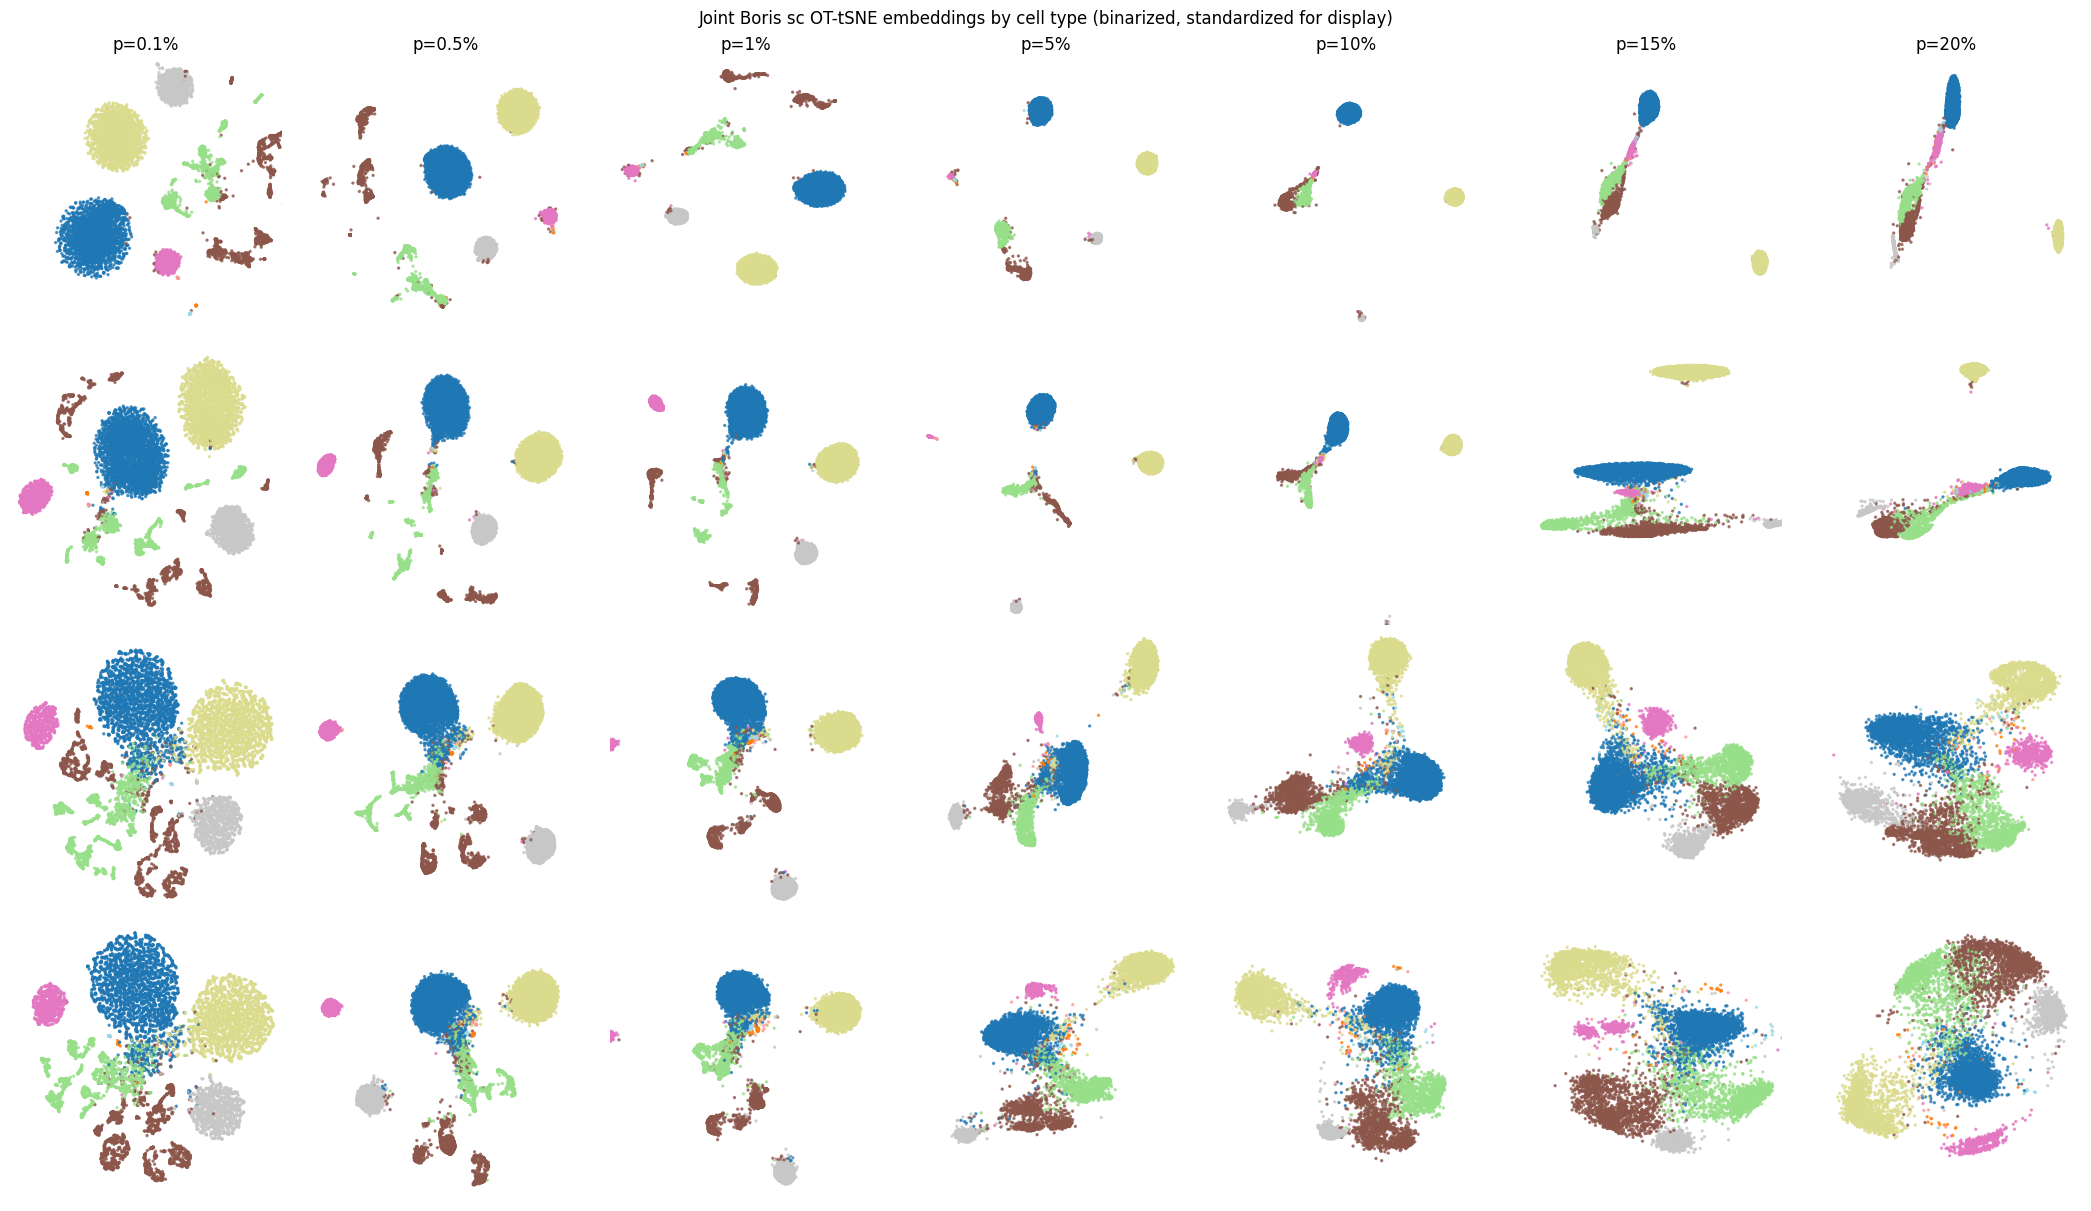

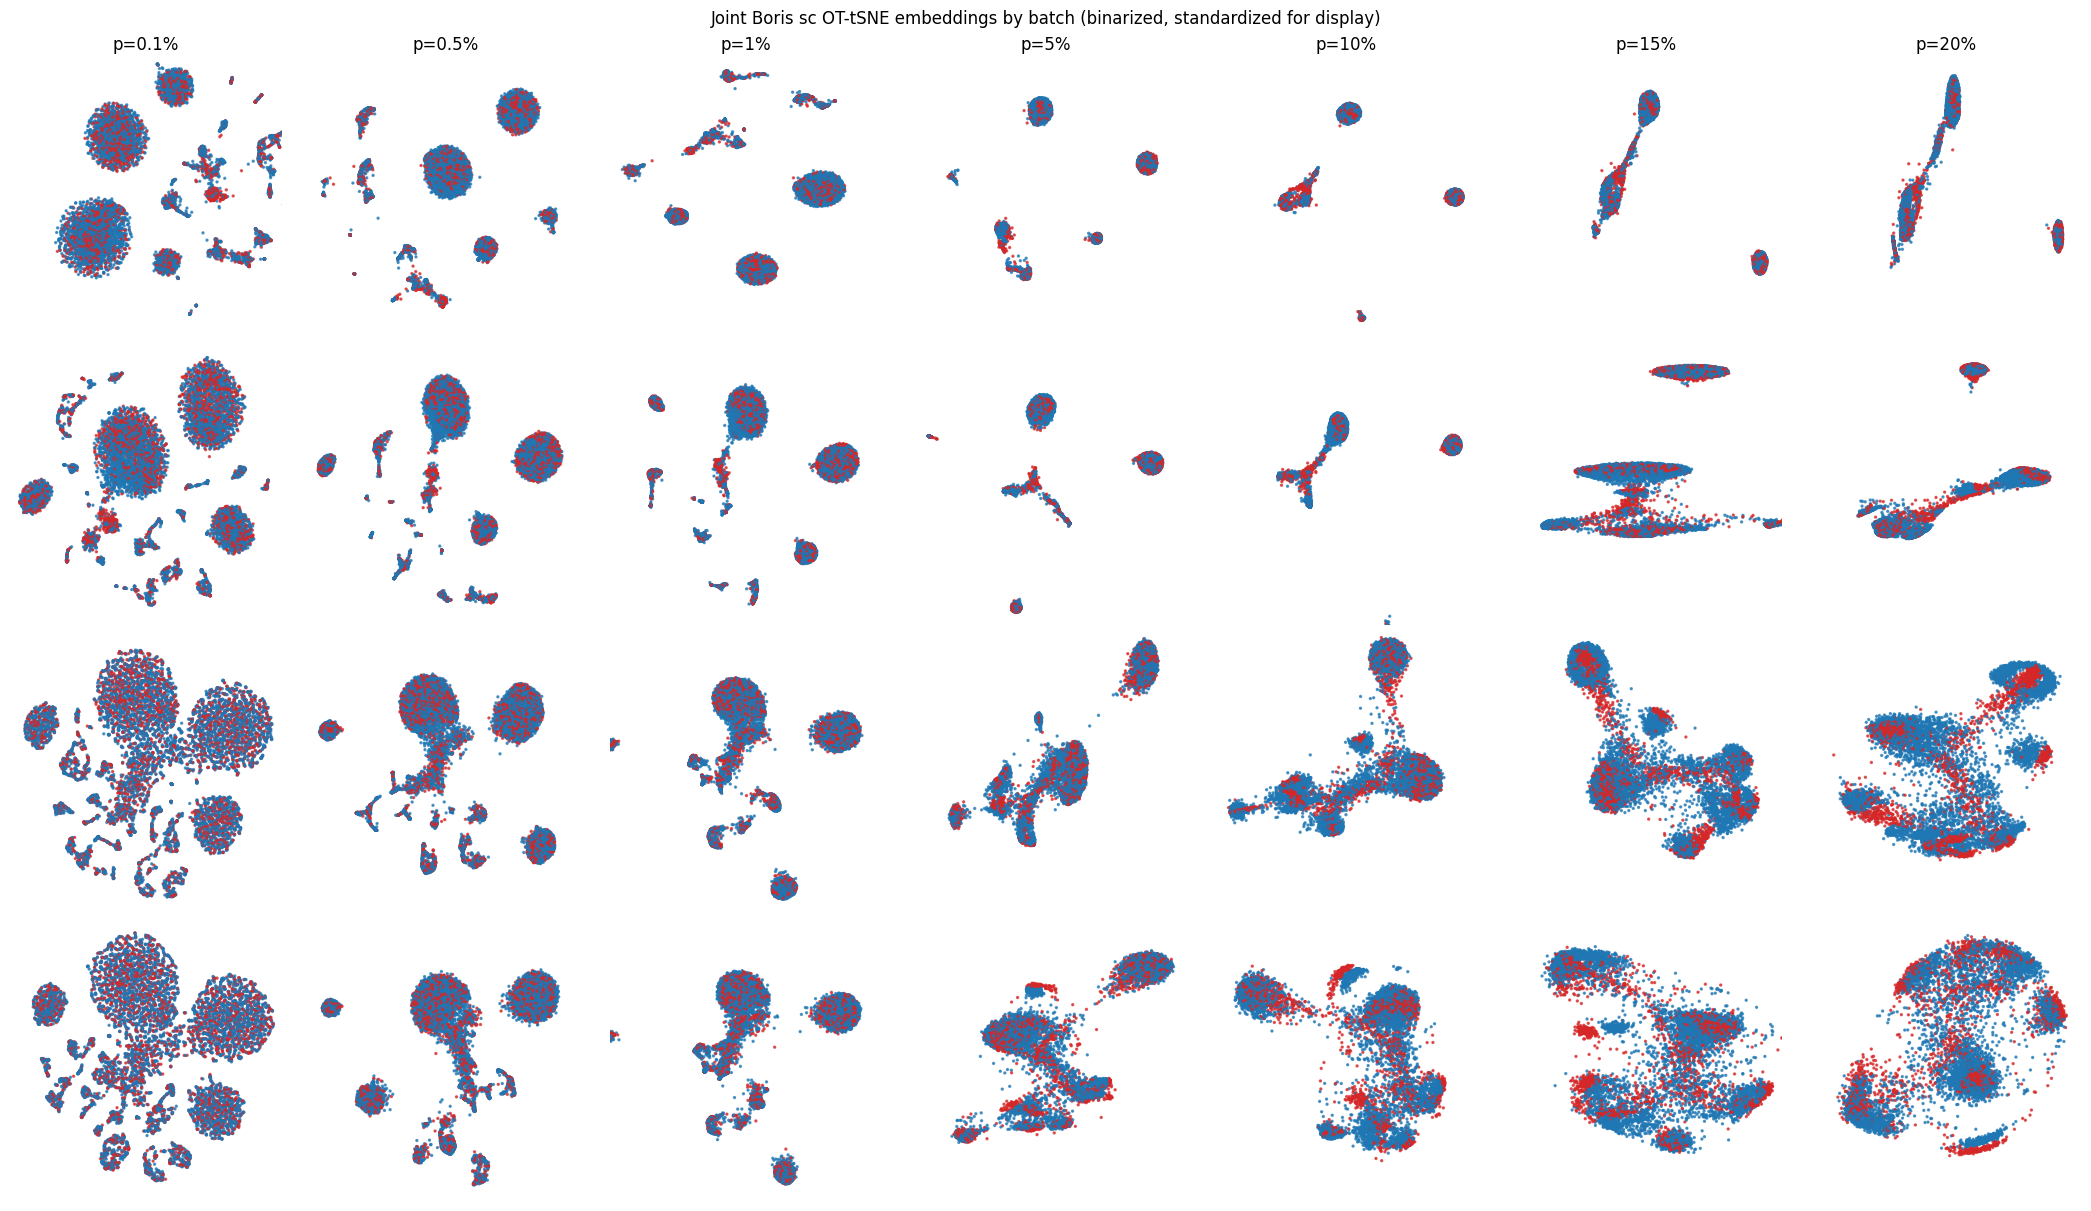

Saved OT-tSNE cell-type embedding grid to /weka/berens/bep526/ot-tSNE/ne-aligned/data/human_brain/figures/joint_ot_tsne_embedding_grid_cell_type_binarized.png
Saved OT-tSNE batch embedding grid to /weka/berens/bep526/ot-tSNE/ne-aligned/data/human_brain/figures/joint_ot_tsne_embedding_grid_batch_binarized.png


In [7]:
import matplotlib.pyplot as plt
import numpy as np


def standardize_embedding_for_display(embedding, eps=1e-12):
    embedding = np.asarray(embedding, dtype=float)
    centered = embedding - embedding.mean(axis=0, keepdims=True)
    scale = embedding.std(axis=0, keepdims=True)
    scale = np.where(scale < eps, 1.0, scale)
    return centered / scale


def compute_display_bounds(embeddings, lower=1.0, upper=99.0, pad_fraction=0.08):
    x_values = np.asarray(embeddings[..., 0], dtype=float).ravel()
    y_values = np.asarray(embeddings[..., 1], dtype=float).ravel()
    x_min, x_max = np.percentile(x_values, [lower, upper])
    y_min, y_max = np.percentile(y_values, [lower, upper])
    x_pad = pad_fraction * max(float(x_max - x_min), 1.0)
    y_pad = pad_fraction * max(float(y_max - y_min), 1.0)
    return (float(x_min - x_pad), float(x_max + x_pad)), (float(y_min - y_pad), float(y_max + y_pad))


embedding_metric_cache_dir = resolve_human_brain_path()
embedding_metric_figure_dir = embedding_metric_cache_dir / "figures"
embedding_metric_figure_dir.mkdir(parents=True, exist_ok=True)

embedding_metric_variant = globals().get("embedding_metric_variant", "binarized")
embedding_metric_cache_path = (
    embedding_metric_cache_dir
    / f"joint_ot_tsne_sweep_embeddings_{embedding_metric_variant}.npz"
)
if not embedding_metric_cache_path.exists():
    raise FileNotFoundError(
        f"No saved OT-tSNE embedding cache found at {embedding_metric_cache_path}. "
        "Run the embedding cache cell first."
    )

with np.load(embedding_metric_cache_path) as cache:
    embedding_metric_eps_values = np.asarray(cache["eps_values"], dtype=float)
    embedding_metric_percentages = np.asarray(cache["percentages"], dtype=float)
    ot_tsne_metric_embeddings = np.asarray(cache["ot_tsne_embeddings"], dtype=float)

ot_tsne_display_embeddings = np.empty_like(ot_tsne_metric_embeddings)
for eps_idx in range(len(embedding_metric_eps_values)):
    for pct_idx in range(len(embedding_metric_percentages)):
        ot_tsne_display_embeddings[eps_idx, pct_idx] = standardize_embedding_for_display(
            ot_tsne_metric_embeddings[eps_idx, pct_idx]
        )

cell_type_palette = np.array(
    [plt.get_cmap("tab20", len(boris_sc.cell_type_names))(i) for i in range(len(boris_sc.cell_type_names))]
)
batch_palette = np.array(["tab:red", "tab:blue"], dtype=object)
plot_order = np.random.default_rng(0).permutation(boris_sc.joint_data.shape[0])
point_size = 2.0
alpha = 0.7

fig_cell, axes_cell = plt.subplots(
    len(embedding_metric_eps_values),
    len(embedding_metric_percentages),
    figsize=(3.0 * len(embedding_metric_percentages), 3.0 * len(embedding_metric_eps_values)),
    constrained_layout=True,
    squeeze=False,
)

fig_batch, axes_batch = plt.subplots(
    len(embedding_metric_eps_values),
    len(embedding_metric_percentages),
    figsize=(3.0 * len(embedding_metric_percentages), 3.0 * len(embedding_metric_eps_values)),
    constrained_layout=True,
    squeeze=False,
)

for row_idx, eps_times in enumerate(embedding_metric_eps_values):
    row_x_limits, row_y_limits = compute_display_bounds(
        ot_tsne_display_embeddings[row_idx],
        lower=0.5,
        upper=99.5,
        pad_fraction=0.08,
    )

    for pct_idx, percentage in enumerate(embedding_metric_percentages):
        embedding = ot_tsne_display_embeddings[row_idx, pct_idx]
        ax_cell = axes_cell[row_idx, pct_idx]
        ax_batch = axes_batch[row_idx, pct_idx]

        ax_cell.scatter(
            embedding[plot_order, 0],
            embedding[plot_order, 1],
            s=point_size,
            c=cell_type_palette[boris_sc.joint_labels][plot_order],
            alpha=alpha,
        )
        ax_batch.scatter(
            embedding[plot_order, 0],
            embedding[plot_order, 1],
            s=point_size,
            c=batch_palette[boris_sc.batch_ids][plot_order],
            alpha=alpha,
        )

        if row_idx == 0:
            ax_cell.set_title(f"p={100.0 * percentage:g}%")
            ax_batch.set_title(f"p={100.0 * percentage:g}%")

        if pct_idx == 0:
            ax_cell.set_ylabel(f"eps={eps_times:g}")
            ax_batch.set_ylabel(f"eps={eps_times:g}")

        for ax in (ax_cell, ax_batch):
            ax.set_xlim(*row_x_limits)
            ax.set_ylim(*row_y_limits)
            ax.set_aspect("equal")
            ax.axis("off")

fig_cell.suptitle(
    f"Joint Boris sc OT-tSNE embeddings by cell type ({embedding_metric_variant}, standardized for display)"
)
fig_batch.suptitle(
    f"Joint Boris sc OT-tSNE embeddings by batch ({embedding_metric_variant}, standardized for display)"
)

ot_cell_figure_path = (
    embedding_metric_figure_dir
    / f"joint_ot_tsne_embedding_grid_cell_type_{embedding_metric_variant}.png"
)
ot_batch_figure_path = (
    embedding_metric_figure_dir
    / f"joint_ot_tsne_embedding_grid_batch_{embedding_metric_variant}.png"
)
fig_cell.savefig(ot_cell_figure_path, bbox_inches="tight")
fig_batch.savefig(ot_batch_figure_path, bbox_inches="tight")
plt.show()
print(f"Saved OT-tSNE cell-type embedding grid to {ot_cell_figure_path}")
print(f"Saved OT-tSNE batch embedding grid to {ot_batch_figure_path}")

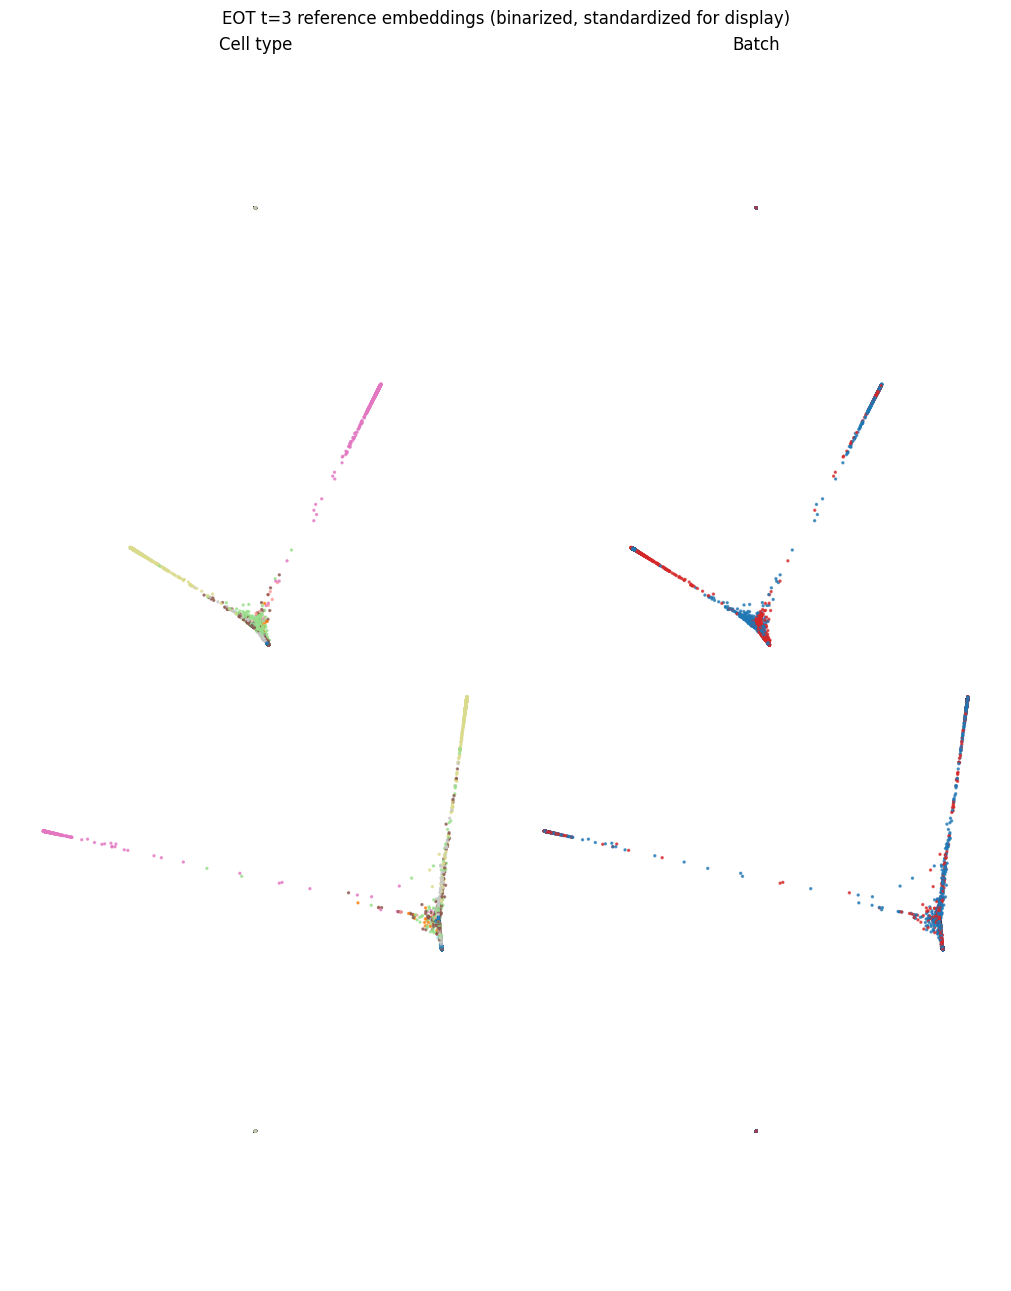

Saved EOT reference embedding figure to /weka/berens/bep526/ot-tSNE/ne-aligned/data/human_brain/figures/eot_t3_reference_embeddings_binarized.png


In [4]:
import matplotlib.pyplot as plt
import numpy as np


def standardize_embedding_for_display(embedding, eps=1e-12):
    embedding = np.asarray(embedding, dtype=float)
    centered = embedding - embedding.mean(axis=0, keepdims=True)
    scale = embedding.std(axis=0, keepdims=True)
    scale = np.where(scale < eps, 1.0, scale)
    return centered / scale


def compute_display_bounds(embeddings, lower=1.0, upper=99.0, pad_fraction=0.08):
    x_values = np.asarray(embeddings[..., 0], dtype=float).ravel()
    y_values = np.asarray(embeddings[..., 1], dtype=float).ravel()
    x_min, x_max = np.percentile(x_values, [lower, upper])
    y_min, y_max = np.percentile(y_values, [lower, upper])
    x_pad = pad_fraction * max(float(x_max - x_min), 1.0)
    y_pad = pad_fraction * max(float(y_max - y_min), 1.0)
    return (float(x_min - x_pad), float(x_max + x_pad)), (float(y_min - y_pad), float(y_max + y_pad))


def is_degenerate_embedding(embedding, eps=1e-12):
    embedding = np.asarray(embedding, dtype=float)
    return float(np.max(embedding.std(axis=0))) < eps


embedding_metric_cache_dir = resolve_human_brain_path()
embedding_metric_figure_dir = embedding_metric_cache_dir / "figures"
embedding_metric_figure_dir.mkdir(parents=True, exist_ok=True)

embedding_metric_variant = globals().get("embedding_metric_variant", "binarized")
embedding_metric_cache_path = (
    embedding_metric_cache_dir
    / f"joint_ot_tsne_sweep_embeddings_{embedding_metric_variant}.npz"
)
if not embedding_metric_cache_path.exists():
    raise FileNotFoundError(
        f"No saved OT-tSNE embedding cache found at {embedding_metric_cache_path}. "
        "Run the embedding cache cell first."
    )

with np.load(embedding_metric_cache_path) as cache:
    embedding_metric_eps_values = np.asarray(cache["eps_values"], dtype=float)
    eot_metric_embeddings = np.asarray(cache["eot_embeddings"], dtype=float)
    embedding_metric_eot_t = int(cache["eot_t"])

eot_display_embeddings = np.empty_like(eot_metric_embeddings)
degenerate_rows = []
for eps_idx in range(len(embedding_metric_eps_values)):
    eot_display_embeddings[eps_idx] = standardize_embedding_for_display(
        eot_metric_embeddings[eps_idx]
    )
    if is_degenerate_embedding(eot_metric_embeddings[eps_idx]):
        degenerate_rows.append(float(embedding_metric_eps_values[eps_idx]))

cell_type_palette = np.array(
    [plt.get_cmap("tab20", len(boris_sc.cell_type_names))(i) for i in range(len(boris_sc.cell_type_names))]
)
batch_palette = np.array(["tab:red", "tab:blue"], dtype=object)
plot_order = np.random.default_rng(0).permutation(boris_sc.joint_data.shape[0])
point_size = 2.0
alpha = 0.7

fig, axes = plt.subplots(
    len(embedding_metric_eps_values),
    2,
    figsize=(10, 3.2 * len(embedding_metric_eps_values)),
    constrained_layout=True,
    squeeze=False,
)

for row_idx, eps_times in enumerate(embedding_metric_eps_values):
    raw_embedding = eot_metric_embeddings[row_idx]
    embedding = eot_display_embeddings[row_idx]
    row_is_degenerate = is_degenerate_embedding(raw_embedding)

    if row_is_degenerate:
        for ax, label in zip(axes[row_idx], ["Cell type", "Batch"]):
            ax.scatter([0.0], [0.0], s=10.0, c="black", alpha=0.8)
            ax.text(
                0.0,
                0.18,
                "collapsed EOT embedding",
                ha="center",
                va="bottom",
                fontsize=9,
            )
            ax.set_xlim(-1.0, 1.0)
            ax.set_ylim(-1.0, 1.0)
            ax.set_aspect("equal")
            ax.axis("off")
    else:
        row_x_limits, row_y_limits = compute_display_bounds(
            embedding,
            lower=0.5,
            upper=99.5,
            pad_fraction=0.08,
        )

        axes[row_idx, 0].scatter(
            embedding[plot_order, 0],
            embedding[plot_order, 1],
            s=point_size,
            c=cell_type_palette[boris_sc.joint_labels][plot_order],
            alpha=alpha,
        )
        axes[row_idx, 1].scatter(
            embedding[plot_order, 0],
            embedding[plot_order, 1],
            s=point_size,
            c=batch_palette[boris_sc.batch_ids][plot_order],
            alpha=alpha,
        )

        for ax in axes[row_idx]:
            ax.set_xlim(*row_x_limits)
            ax.set_ylim(*row_y_limits)
            ax.set_aspect("equal")
            ax.axis("off")

    if row_idx == 0:
        axes[row_idx, 0].set_title("Cell type")
        axes[row_idx, 1].set_title("Batch")

    axes[row_idx, 0].set_ylabel(f"eps={eps_times:g}")

fig.suptitle(
    f"EOT t={embedding_metric_eot_t} reference embeddings ({embedding_metric_variant}, standardized for display)"
)

eot_reference_figure_path = (
    embedding_metric_figure_dir
    / f"eot_t{embedding_metric_eot_t}_reference_embeddings_{embedding_metric_variant}.png"
)
fig.savefig(eot_reference_figure_path, bbox_inches="tight")
plt.show()
if degenerate_rows:
    print("Degenerate EOT rows:", ", ".join(f"eps={eps:g}" for eps in degenerate_rows))
print(f"Saved EOT reference embedding figure to {eot_reference_figure_path}")